# Poço com gas lift: intermitência forte (complemento ao caso 10.3.2)

No cenário 2 da tese (choke de gás 75 % → 15 %) o poço passa a operar de forma
intermitente. Aqui a restrição é maior (choke de gás a **12 %** e a **10 %**) e
a simulação é longa (16 000 s) para capturar vários ciclos de *heading*:

1. com pouco gás injetado, a coluna no tubing fica pesada e a produção cai;
2. a pressão no anular (vértice 8) sobe lentamente até vencer a pressão do
   tubing na válvula de retenção;
3. o gás acumulado é injetado de uma vez, aliviando a coluna: a produção de
   líquido dispara (pico de ~23 kg/s contra 0.2–0.6 kg/s no mínimo);
4. o anular se esvazia, a injeção cessa e o ciclo recomeça.

Mesma rede do caso 10.3.2 (diferenças finitas centrais, modelo a 3 equações
no tubing, monofásicos nas linhas de gás, válvula de retenção regularizada).
Tolerância relativa 1e-3 (BDF2); o integrador atravessa os transientes rápidos
em cerca de um minuto de CPU por simulação.

In [1]:
import numpy as np, matplotlib.pyplot as plt, time, warnings

warnings.filterwarnings("ignore")
from mfsim.io_legacy import chapter10_case
from mfsim.simulation import build_model, state_bounds
from mfsim.integrators.implicit import ImplicitBDF
from mfsim.results import Results
from mfsim.network.graph import Choke
from mfsim.network.schedules import PiecewiseLinear


def run_gas_lift(opening, tf=16000.0, rtol=1e-3, order=2):
    case = chapter10_case("10.3.2b")
    case.set_time(tf=tf)
    for v in case.edges_of(Choke):
        if v.v_to == "6":  # choke de gás
            v.opening = PiecewiseLinear(np.array([0.0, 100.0, 150.0, tf]), np.array([0.75, 0.75, opening, opening]))
    model = build_model(case)
    bdf = ImplicitBDF(
        model.rhs,
        S=model.jac_sparsity(),
        rtol=rtol,
        atol=rtol * 1e-2,
        bounds=state_bounds(model),
        min_step=1e-9,
        max_order=order,
    )
    t0 = time.time()
    T, X, info = bdf.integrate(np.arange(0, tf + 1, 5.0), model.initial_state(), breakpoints=model.spec_breakpoints())
    print(
        f"abertura {opening:.0%}: {info['n_steps']} passos, {info['n_rejected']} rejeitados, {time.time()-t0:.1f} s de CPU"
    )
    return Results(model, T, X, info)


runs = {ab: run_gas_lift(ab) for ab in (0.12, 0.10)}

abertura 12%: 2897 passos, 543 rejeitados, 76.1 s de CPU


abertura 10%: 3561 passos, 684 rejeitados, 85.6 s de CPU


## Produção de líquido, injeção de gás e pressões

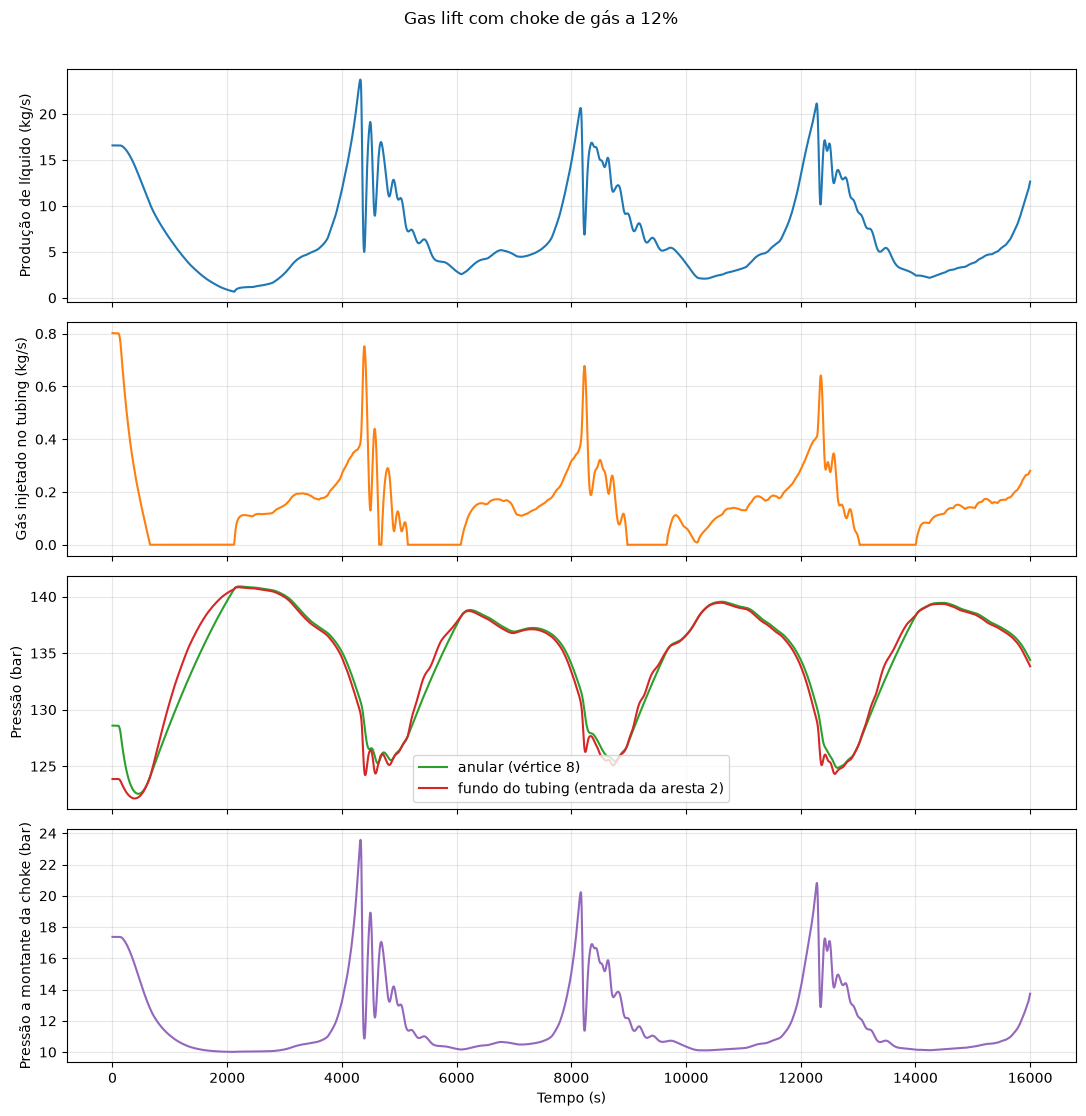

abertura 12%: produção média 6.86 kg/s, mín 0.68, máx 23.74, desvio padrão 4.78


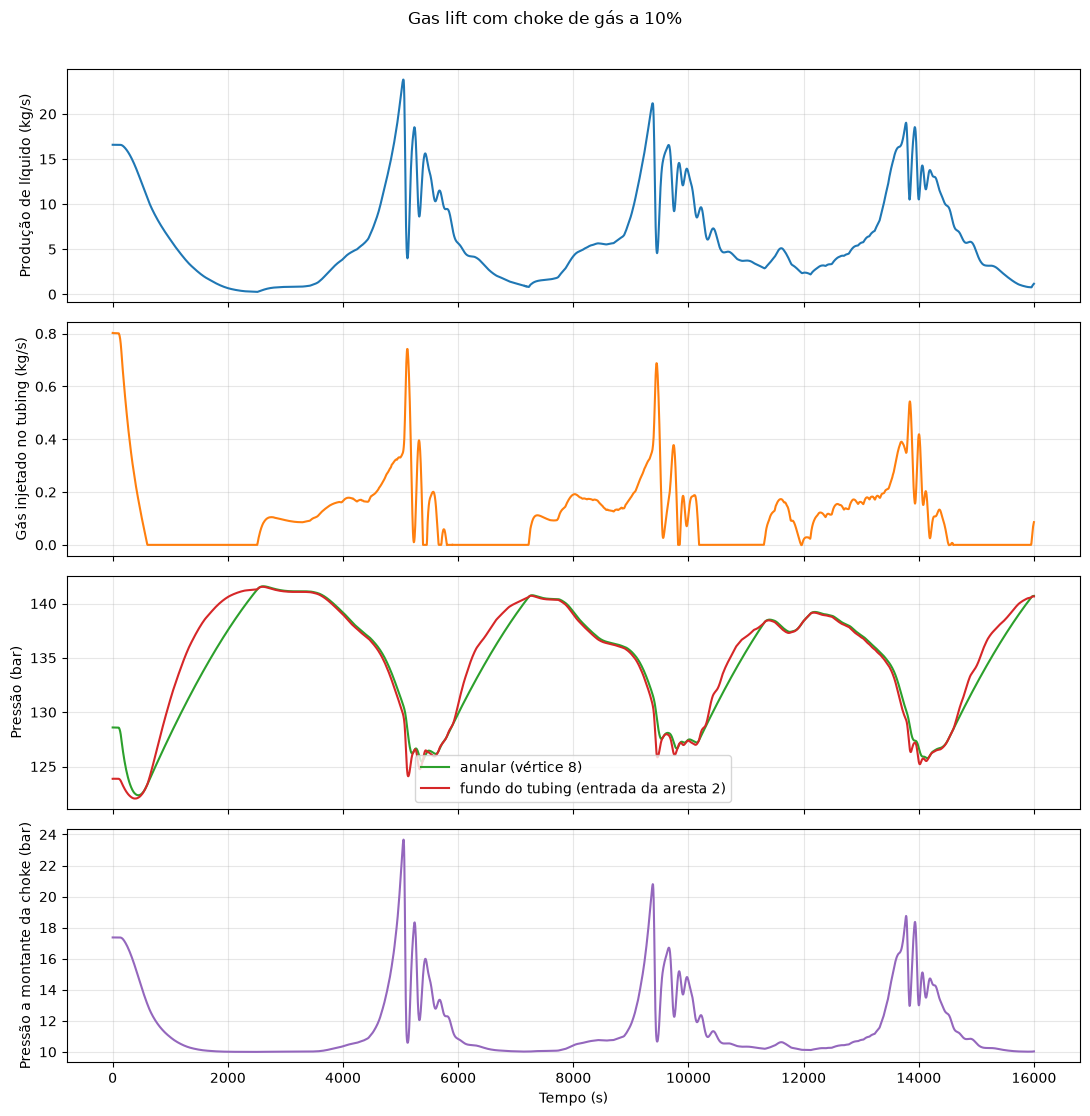

abertura 10%: produção média 6.04 kg/s, mín 0.27, máx 23.81, desvio padrão 4.99


In [2]:
for ab, res in runs.items():
    T = res.T
    choke = res.elements["valves"][4]  # choke de produção (vértice 4)
    gl = res.elements["check_valves"][8]  # válvula de gas lift (vértice 8)
    fig, axes = plt.subplots(4, 1, figsize=(11, 11), sharex=True)
    axes[0].plot(T, choke["qL"])
    axes[0].set_ylabel("Produção de líquido (kg/s)")
    axes[1].plot(T, gl["qG"], color="C1")
    axes[1].set_ylabel("Gás injetado no tubing (kg/s)")
    axes[2].plot(T, gl["ZP"], color="C2", label="anular (vértice 8)")
    axes[2].plot(T, res.pipe(1)["out"]["P_bar"][0], color="C3", label="fundo do tubing (entrada da aresta 2)")
    axes[2].set_ylabel("Pressão (bar)")
    axes[2].legend()
    axes[3].plot(T, choke["ZP"], color="C4")
    axes[3].set_ylabel("Pressão a montante da choke (bar)")
    axes[3].set_xlabel("Tempo (s)")
    for ax in axes:
        ax.grid(alpha=0.3)
    fig.suptitle(f"Gas lift com choke de gás a {ab:.0%}", y=1.01)
    fig.tight_layout()
    plt.show()
    sel = T > 2000
    q = choke["qL"][sel]
    print(
        f"abertura {ab:.0%}: produção média {q.mean():.2f} kg/s, mín {q.min():.2f}, máx {q.max():.2f}, desvio padrão {q.std():.2f}"
    )

## Fração de gás e vazão de líquido ao longo do tubing (choke a 12 %)

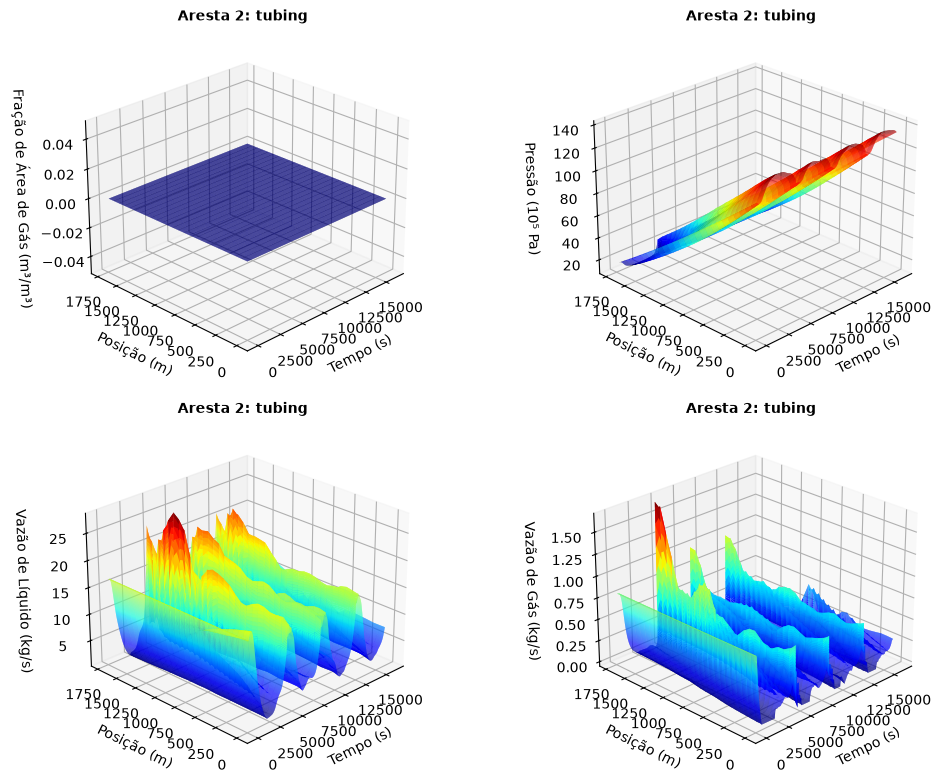

In [3]:
from mfsim.plotting import pipe_surfaces

res = runs[0.12]
fig = pipe_surfaces(res, 1, keys=("alphaG", "P_bar", "qL", "qG"), title="Aresta 2: tubing")
plt.show()

## Período dos ciclos
Estimativa do período pela autocorrelação da produção de líquido (após 2000 s).

In [4]:
for ab, res in runs.items():
    T = res.T
    q = res.elements["valves"][4]["qL"]
    sel = T > 2000
    s = q[sel] - q[sel].mean()
    ac = np.correlate(s, s, mode="full")[s.size - 1 :]
    ac /= ac[0]
    dt = T[1] - T[0]
    # primeiro máximo local após o primeiro mínimo
    i_min = np.argmin(ac[: ac.size // 2])
    i_max = i_min + np.argmax(ac[i_min : ac.size // 2])
    print(f"abertura {ab:.0%}: período estimado ≈ {i_max * dt:.0f} s (autocorrelação {ac[i_max]:.2f})")

abertura 12%: período estimado ≈ 3850 s (autocorrelação 0.61)
abertura 10%: período estimado ≈ 4350 s (autocorrelação 0.60)


## Lado direito compilado (JAX)
O caso com choke a 12 % repetido com o lado direito compilado e a Jacobiana exata
(`mfsim.compiled.get_jax`), passando `jac_fun` ao integrador.

abertura 12% (JAX): 2914 passos, 567 rejeitados, 8.0 s de CPU (compilação 0.9 s)
diferença máxima relativa dos estados numpy x JAX: 3.7e-01


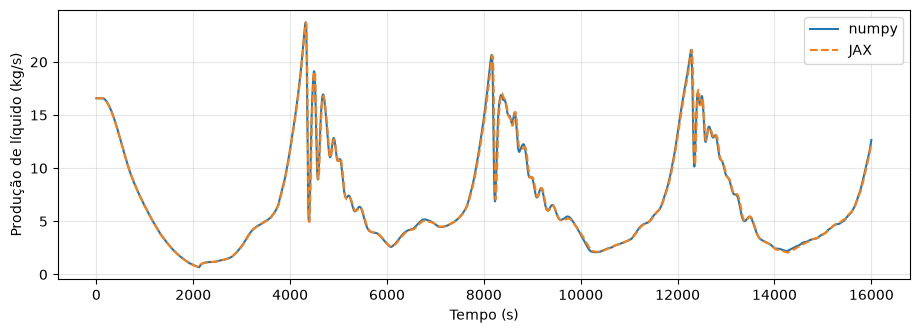

In [5]:
from mfsim.compiled import get_jax


def run_gas_lift_jax(opening, tf=16000.0, rtol=1e-3, order=2):
    case = chapter10_case("10.3.2b")
    case.set_time(tf=tf)
    for v in case.edges_of(Choke):
        if v.v_to == "6":
            v.opening = PiecewiseLinear(np.array([0.0, 100.0, 150.0, tf]), np.array([0.75, 0.75, opening, opening]))
    model = build_model(case)
    t0 = time.time()
    rhs_j, jac_j = get_jax(model)
    x0 = model.initial_state()
    rhs_j(0.0, x0)
    jac_j(0.0, x0)
    t_compile = time.time() - t0
    bdf = ImplicitBDF(
        rhs_j,
        S=model.jac_sparsity(),
        rtol=rtol,
        atol=rtol * 1e-2,
        bounds=state_bounds(model),
        min_step=1e-9,
        max_order=order,
        jac_fun=jac_j,
    )
    t0 = time.time()
    T, X, info = bdf.integrate(np.arange(0, tf + 1, 5.0), model.initial_state(), breakpoints=model.spec_breakpoints())
    print(
        f"abertura {opening:.0%} (JAX): {info['n_steps']} passos, {info['n_rejected']} rejeitados, {time.time()-t0:.1f} s de CPU (compilação {t_compile:.1f} s)"
    )
    return Results(model, T, X, info)


res_j = run_gas_lift_jax(0.12)
res_n = runs[0.12]
n = min(res_n.X.shape[1], res_j.X.shape[1])
scale = np.max(np.abs(res_n.X), axis=1) + 1e-12
print(
    f"diferença máxima relativa dos estados numpy x JAX: {np.max(np.abs(res_n.X[:, :n] - res_j.X[:, :n]) / scale[:, None]):.1e}"
)
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(res_n.T, res_n.elements["valves"][4]["qL"], label="numpy")
ax.plot(res_j.T, res_j.elements["valves"][4]["qL"], "--", label="JAX")
ax.set_xlabel("Tempo (s)")
ax.set_ylabel("Produção de líquido (kg/s)")
ax.legend()
ax.grid(alpha=0.3)
plt.show()